              precision    recall  f1-score   support

   Stay (No)       0.92      0.94      0.93       309
 Leave (Yes)       0.63      0.56      0.59        59

    accuracy                           0.88       368
   macro avg       0.78      0.75      0.76       368
weighted avg       0.87      0.88      0.87       368

ROC-AUC: 0.8731
Salary MAE: 30523.93
Salary R2: 0.8045


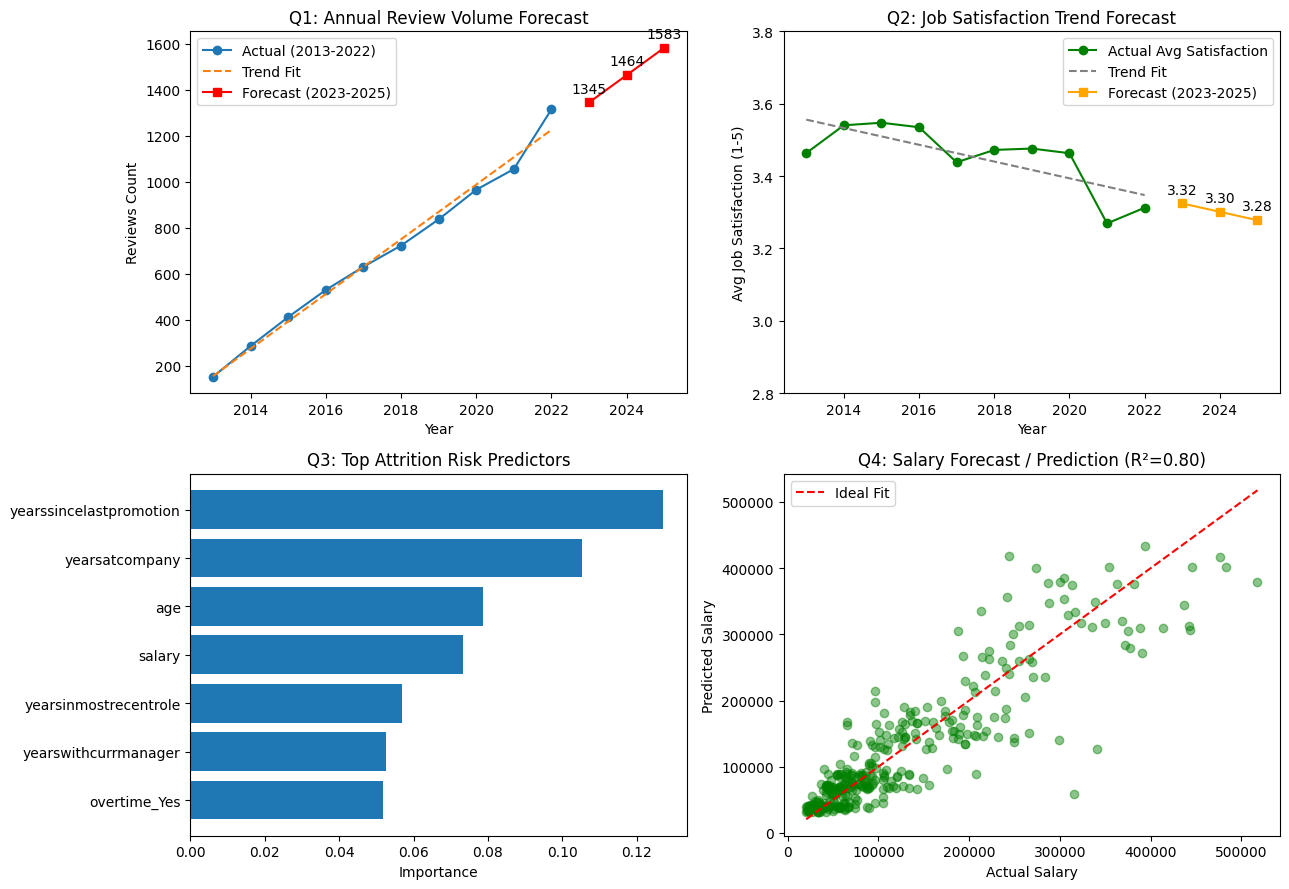

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    mean_absolute_error,
    r2_score,
)

df = pd.read_csv('/content/hr_dataset_cleaned.csv')
df['reviewdate_dt'] = pd.to_datetime(df['reviewdate'], errors='coerce')
df['review_year'] = df['reviewdate_dt'].dt.year

emp_df = (
    df.sort_values(['employeeid', 'reviewdate_dt'])
    .groupby('employeeid')
    .tail(1)
    .copy()
)

yearly = (
    df.groupby('review_year')
    .agg(
        review_count=('performanceid', 'count'),
        avg_job_sat=('jobsatisfaction', 'mean'),
    )
    .reset_index()
)

X_yr = yearly[['review_year']].values
fut_yr = np.array([[2023], [2024], [2025]])

lr_cnt = LinearRegression().fit(X_yr, yearly['review_count'].values)
pred_cnt_hist = lr_cnt.predict(X_yr)
pred_cnt_fut = lr_cnt.predict(fut_yr)

lr_sat = LinearRegression().fit(X_yr, yearly['avg_job_sat'].values)
pred_sat_hist = lr_sat.predict(X_yr)
pred_sat_fut = lr_sat.predict(fut_yr)

y_attr = (emp_df['attrition'] == 'Yes').astype(int)
num_cols_attr = [
    'age',
    'salary',
    'yearsatcompany',
    'yearsinmostrecentrole',
    'yearssincelastpromotion',
    'yearswithcurrmanager',
    'distancefromhome_km',
    'jobsatisfaction',
    'worklifebalance',
    'environmentsatisfaction',
    'managerrating',
    'trainingopportunitiestaken',
]
cat_cols_attr = [
    'department',
    'jobrole',
    'overtime',
    'businesstravel',
    'maritalstatus',
    'educationlevel',
]

X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    emp_df[num_cols_attr + cat_cols_attr],
    y_attr,
    test_size=0.25,
    random_state=42,
    stratify=y_attr,
)

prep_attr = ColumnTransformer([
    ('num', 'passthrough', num_cols_attr),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols_attr),
])

clf_attr = Pipeline([
    ('prep', prep_attr),
    (
        'rf',
        RandomForestClassifier(
            n_estimators=300,
            max_depth=8,
            random_state=42,
            class_weight='balanced',
        ),
    ),
])
clf_attr.fit(X_train_a, y_train_a)

y_pred_a = clf_attr.predict(X_test_a)
y_prob_a = clf_attr.predict_proba(X_test_a)[:, 1]
print(
    classification_report(
        y_test_a, y_pred_a, target_names=['Stay (No)', 'Leave (Yes)']
    )
)
print('ROC-AUC:', round(roc_auc_score(y_test_a, y_prob_a), 4))

num_cols_sal = [
    'age',
    'yearsatcompany',
    'yearsinmostrecentrole',
    'yearssincelastpromotion',
    'yearswithcurrmanager',
    'managerrating',
    'trainingopportunitiestaken',
]
cat_cols_sal = [
    'department',
    'jobrole',
    'educationlevel',
    'gender',
    'overtime',
]

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    emp_df[num_cols_sal + cat_cols_sal],
    emp_df['salary'],
    test_size=0.25,
    random_state=42,
)

prep_sal = ColumnTransformer([
    ('num', 'passthrough', num_cols_sal),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols_sal),
])

reg_sal = Pipeline([
    ('prep', prep_sal),
    (
        'rf',
        RandomForestRegressor(n_estimators=300, max_depth=10, random_state=42),
    ),
])
reg_sal.fit(X_train_s, y_train_s)
y_pred_s = reg_sal.predict(X_test_s)
print('Salary MAE:', round(mean_absolute_error(y_test_s, y_pred_s), 2))
print('Salary R2:', round(r2_score(y_test_s, y_pred_s), 4))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].plot(
    yearly['review_year'],
    yearly['review_count'],
    marker='o',
    label='Actual (2013-2022)',
)
axes[0, 0].plot(
    yearly['review_year'], pred_cnt_hist, linestyle='--', label='Trend Fit'
)
axes[0, 0].plot(
    [2023, 2024, 2025],
    pred_cnt_fut,
    marker='s',
    label='Forecast (2023-2025)',
    color='red',
)
for x, y in zip([2023, 2024, 2025], pred_cnt_fut):
    axes[0, 0].annotate(
        f'{y:.0f}',
        (x, y),
        textcoords='offset points',
        xytext=(0, 7),
        ha='center',
    )
axes[0, 0].set_title('Q1: Annual Review Volume Forecast')
axes[0, 0].set_xlabel('Year')
axes[0, 0].set_ylabel('Reviews Count')
axes[0, 0].legend()

axes[0, 1].plot(
    yearly['review_year'],
    yearly['avg_job_sat'],
    marker='o',
    label='Actual Avg Satisfaction',
    color='green',
)
axes[0, 1].plot(
    yearly['review_year'],
    pred_sat_hist,
    linestyle='--',
    label='Trend Fit',
    color='gray',
)
axes[0, 1].plot(
    [2023, 2024, 2025],
    pred_sat_fut,
    marker='s',
    label='Forecast (2023-2025)',
    color='orange',
)
for x, y in zip([2023, 2024, 2025], pred_sat_fut):
    axes[0, 1].annotate(
        f'{y:.2f}',
        (x, y),
        textcoords='offset points',
        xytext=(0, 7),
        ha='center',
    )
axes[0, 1].set_ylim(2.8, 3.8)
axes[0, 1].set_title('Q2: Job Satisfaction Trend Forecast')
axes[0, 1].set_xlabel('Year')
axes[0, 1].set_ylabel('Avg Job Satisfaction (1-5)')
axes[0, 1].legend()

ohe_cols = (
    clf_attr.named_steps['prep']
    .named_transformers_['cat']
    .get_feature_names_out(cat_cols_attr)
)
feat_names = list(num_cols_attr) + list(ohe_cols)
imp = (
    pd.Series(
        clf_attr.named_steps['rf'].feature_importances_, index=feat_names
    )
    .sort_values(ascending=True)
    .tail(7)
)
axes[1, 0].barh(imp.index, imp.values)
axes[1, 0].set_title('Q3: Top Attrition Risk Predictors')
axes[1, 0].set_xlabel('Importance')

axes[1, 1].scatter(y_test_s, y_pred_s, alpha=0.45, color='green')
mn, mx = min(y_test_s.min(), y_pred_s.min()), max(
    y_test_s.max(), y_pred_s.max()
)
axes[1, 1].plot(
    [mn, mx], [mn, mx], linestyle='--', color='red', label='Ideal Fit'
)
axes[1, 1].set_title(
    f'Q4: Salary Forecast / Prediction (R²={r2_score(y_test_s, y_pred_s):.2f})'
)
axes[1, 1].set_xlabel('Actual Salary')
axes[1, 1].set_ylabel('Predicted Salary')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('week3_forecasting_summary.png', dpi=140)
plt.show()